<a href="https://colab.research.google.com/github/kimve1969/PINN/blob/main/msu-pinn-2d-heat.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Аттестационная работа по DS & ML
#### МГУ, декабрь 2026, В.Е.Ким


In [1]:
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import time
import matplotlib.pyplot as plt

# ================================================================
# ОБЩИЕ ПАРАМЕТРЫ
# ================================================================
alpha = 0.01
Lx, Ly = 1.0, 1.0
T_final = 1.0

# Сетка (одинаковая для обеих схем — для честного сравнения)
Nx, Ny = 51, 51
dx = Lx / (Nx - 1)
dy = Ly / (Ny - 1)

x = np.linspace(0, Lx, Nx)
y = np.linspace(0, Ly, Ny)
X, Y = np.meshgrid(x, y, indexing='ij')


In [19]:
X

array([[0.  , 0.  , 0.  , ..., 0.  , 0.  , 0.  ],
       [0.02, 0.02, 0.02, ..., 0.02, 0.02, 0.02],
       [0.04, 0.04, 0.04, ..., 0.04, 0.04, 0.04],
       ...,
       [0.96, 0.96, 0.96, ..., 0.96, 0.96, 0.96],
       [0.98, 0.98, 0.98, ..., 0.98, 0.98, 0.98],
       [1.  , 1.  , 1.  , ..., 1.  , 1.  , 1.  ]])

In [12]:
Y

array([[0.  , 0.02, 0.04, ..., 0.96, 0.98, 1.  ],
       [0.  , 0.02, 0.04, ..., 0.96, 0.98, 1.  ],
       [0.  , 0.02, 0.04, ..., 0.96, 0.98, 1.  ],
       ...,
       [0.  , 0.02, 0.04, ..., 0.96, 0.98, 1.  ],
       [0.  , 0.02, 0.04, ..., 0.96, 0.98, 1.  ],
       [0.  , 0.02, 0.04, ..., 0.96, 0.98, 1.  ]])

In [38]:
Z = np.exp(-100 * ((X - 0.5)**2 + (Y - 0.5)**2))
Z.max()

np.float64(1.0)

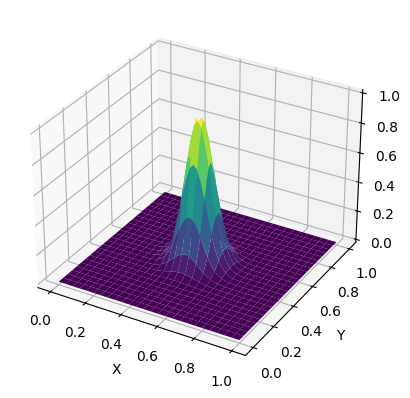

In [37]:
fig = plt.figure()
ax = fig.add_subplot(111,projection='3d')

# Поверхность
ax.plot_surface(X, Y, Z, cmap='viridis')
ax.set_xlabel('X'); ax.set_ylabel('Y'); ax.set_zlabel('Z')
plt.show()